In [ ]:
BRANCH = "main"

%cd /tmp
!rm -rf damage-detection
!git clone -b {BRANCH} https://github.com/azrairemd/damage-detection.git
%cd damage-detection
!pip install -q -r requirements.txt
!pip install -q -e .

/tmp
Cloning into 'damage-detection'...
remote: Enumerating objects: 435, done.
remote: Counting objects: 100% (274/274), done.
remote: Compressing objects: 100% (223/223), done.
remote: Total 435 (delta 116), reused 162 (delta 50), pack-reused 161 (from 1)
Receiving objects: 100% (435/435), 21.39 MiB | 33.08 MiB/s, done.
Resolving deltas: 100% (195/195), done.
/tmp/damage-detection
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for damage-detection (pyproject.toml) ... done


In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM

from src.models.siamese_unet import SiameseUNet
from src.models.baseline_unet import BaselineUNet
from src.data.dataset import XBDDataset
from src.xai.gradcam import SiameseWrapper, get_target_layer, compute_gradcam, heat_on_buildings, measure_groups, measure_pairs
from src.xai.plots import plot_example, plot_comparison, CLASS_NAMES

XBD_ROOT = "/kaggle/input/datasets/qianlanzz/xbd-dataset/xbd"
MASK_ROOT = "/kaggle/input/notebooks/azra41221/03-preprocessing-split/masks"
FD_PATH = "/kaggle/input/notebooks/azra41221/06c-train-siamese-fd/outputs/siamese_concat_fd40/best.pt"
BASELINE_PATH = "/kaggle/input/datasets/azra41221/baseline-checkpoint/best.pt"
device = "cuda"

siamese = SiameseUNet(fusion="concat")
siamese.load_state_dict(torch.load(FD_PATH, map_location=device))
siamese = siamese.to(device).eval()

baseline = BaselineUNet()
baseline.load_state_dict(torch.load(BASELINE_PATH, map_location=device))
baseline = baseline.to(device).eval()

siamese_wrapper = SiameseWrapper(siamese)
baseline_wrapper = SiameseWrapper(baseline)

siamese_cam = GradCAM(model=siamese_wrapper, target_layers=[get_target_layer(siamese)])
baseline_cam = GradCAM(model=baseline_wrapper, target_layers=[get_target_layer(baseline)])

test_set = XBDDataset("splits/test.csv", XBD_ROOT, MASK_ROOT, train=False)

Test images: 2207


In [4]:
groups = [("wind", 2), ("flooding", 3), ("fire", 4), ("tsunami", 4), ("wind", 4)]

siamese_results = measure_groups(siamese_cam, siamese_wrapper, test_set, groups, device)
baseline_results = measure_pairs(baseline_cam, baseline_wrapper, test_set, siamese_results, device)

for (t, c) in groups:
    for name, results in [("Siamese", siamese_results), ("Baseline", baseline_results)]:
        values = results[(t, c)]
        heat = round(np.mean([h for (i, h, a) in values]) * 100, 1)
        area = round(np.mean([a for (i, h, a) in values]) * 100, 1)
        print(t, CLASS_NAMES[c], "|", name, "| images:", len(values), "| heat:", heat, "| area:", area)

wind minor | Siamese | images: 20 | heat: 17.9 | area: 6.8
wind minor | Baseline | images: 14 | heat: 28.0 | area: 6.5
flooding major | Siamese | images: 20 | heat: 19.7 | area: 10.4
flooding major | Baseline | images: 15 | heat: 33.8 | area: 9.4
fire destroyed | Siamese | images: 20 | heat: 6.1 | area: 3.1
fire destroyed | Baseline | images: 19 | heat: 12.4 | area: 3.3
tsunami destroyed | Siamese | images: 20 | heat: 12.0 | area: 14.2
tsunami destroyed | Baseline | images: 20 | heat: 13.9 | area: 14.2
wind destroyed | Siamese | images: 20 | heat: 13.7 | area: 8.7
wind destroyed | Baseline | images: 18 | heat: 17.3 | area: 8.4


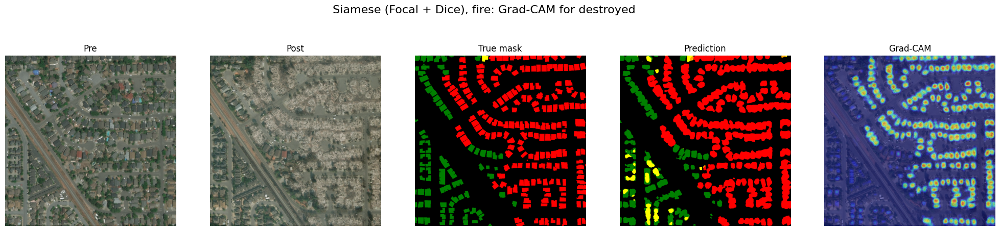

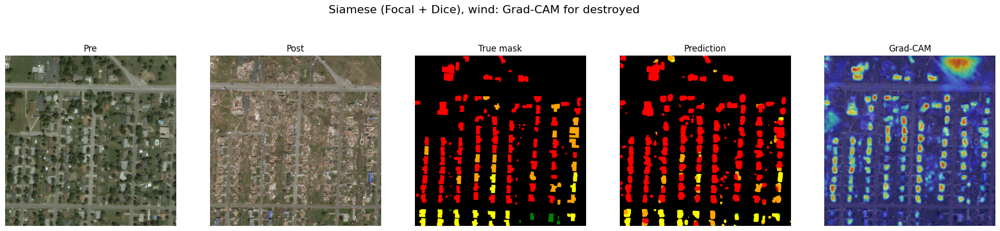

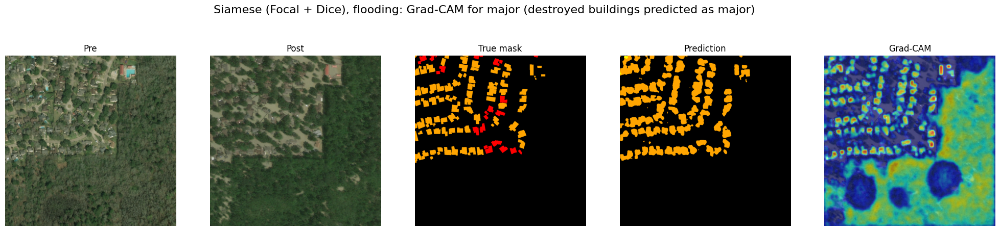

In [5]:
import os
from src.xai.plots import to_image
from pytorch_grad_cam.utils.image import show_cam_on_image

FIG_DIR = "/kaggle/working/figures/"
os.makedirs(FIG_DIR, exist_ok=True)

def load_x(idx):
    pre, post, mask = test_set[idx]
    x = torch.cat([pre, post], dim=0).unsqueeze(0).to(device)
    return pre, post, mask.numpy(), x

def save_example(idx, category, title, file_name):
    pre, post, mask, x = load_x(idx)
    heatmap, pred = compute_gradcam(siamese_cam, siamese_wrapper, x, category)
    plot_example(pre, post, mask, pred, heatmap, title, save_path=FIG_DIR + file_name)
    plt.show()

save_example(1617, 4, "Siamese (Focal + Dice), fire: Grad-CAM for destroyed", "gradcam_fire_destroyed.png")
save_example(436, 4, "Siamese (Focal + Dice), wind: Grad-CAM for destroyed", "gradcam_wind_destroyed.png")
save_example(142, 3, "Siamese (Focal + Dice), flooding: Grad-CAM for major (destroyed buildings predicted as major)", "gradcam_flood_major.png")

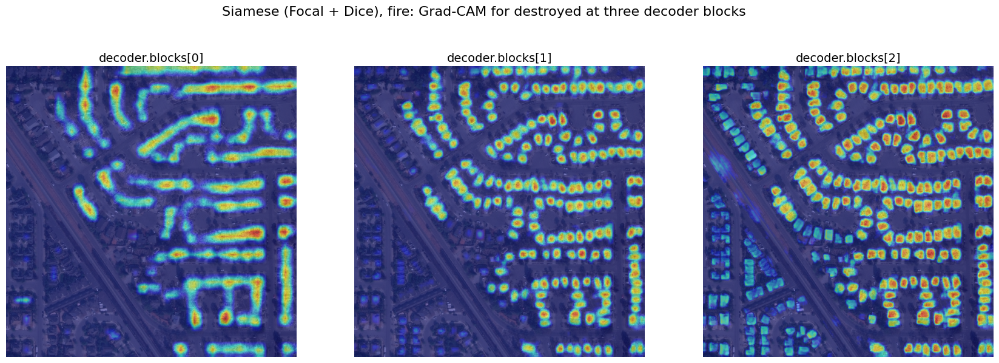

In [6]:
pre, post, mask, x = load_x(1617)
post_img = to_image(post)

fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for k in range(3):
    with GradCAM(model=siamese_wrapper, target_layers=[siamese.decoder.blocks[k]]) as cam_k:
        heatmap_k, _ = compute_gradcam(cam_k, siamese_wrapper, x, 4)
    axes[k].imshow(show_cam_on_image(post_img, heatmap_k, use_rgb=True))
    axes[k].set_title(f"decoder.blocks[{k}]", fontsize=14)
    axes[k].axis("off")

fig.suptitle("Siamese (Focal + Dice), fire: Grad-CAM for destroyed at three decoder blocks", fontsize=16)
plt.savefig(FIG_DIR + "gradcam_layers.png", dpi=150, bbox_inches="tight")
plt.show()

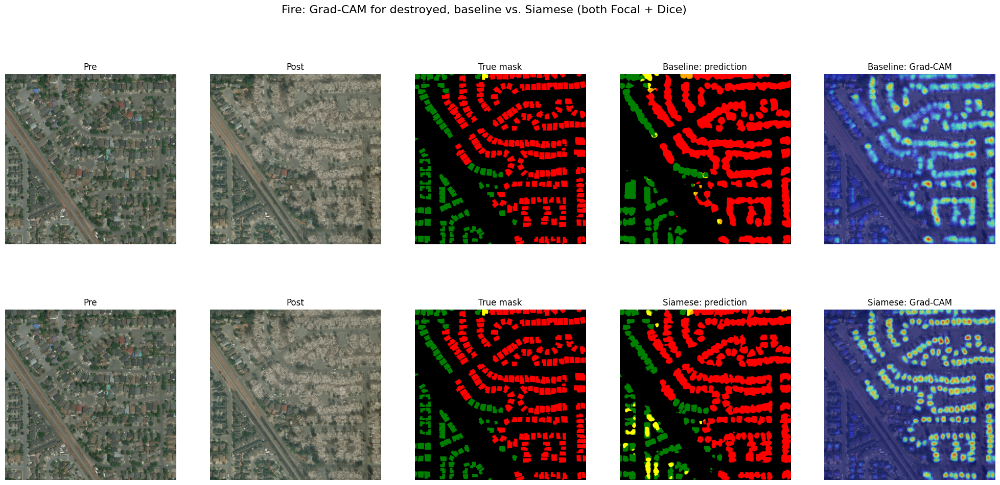

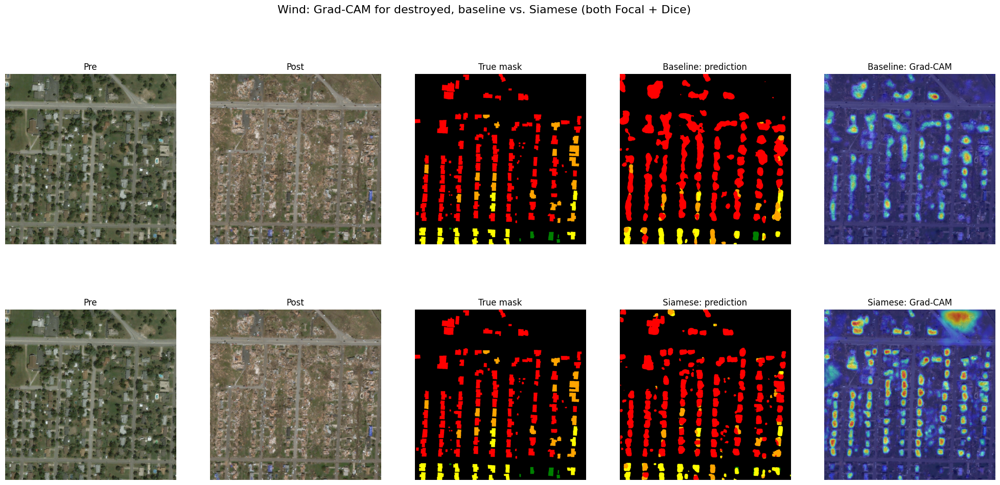

In [7]:
def save_comparison(idx, category, title, file_name):
    pre, post, mask, x = load_x(idx)
    baseline_heatmap, baseline_pred = compute_gradcam(baseline_cam, baseline_wrapper, x, category)
    siamese_heatmap, siamese_pred = compute_gradcam(siamese_cam, siamese_wrapper, x, category)
    plot_comparison(pre, post, mask,
                    [baseline_pred, siamese_pred],
                    [baseline_heatmap, siamese_heatmap],
                    ["Baseline", "Siamese"],
                    title, save_path=FIG_DIR + file_name)
    plt.show()

save_comparison(1617, 4, "Fire: Grad-CAM for destroyed, baseline vs. Siamese (both Focal + Dice)", "gradcam_compare_fire.png")
save_comparison(436, 4, "Wind: Grad-CAM for destroyed, baseline vs. Siamese (both Focal + Dice)", "gradcam_compare_wind.png")

In [8]:
import json

summary = {}
for (t, c) in groups:
    key = t + "_" + CLASS_NAMES[c].replace(" ", "_")
    summary[key] = {}
    for name, results in [("siamese", siamese_results), ("baseline", baseline_results)]:
        values = results[(t, c)]
        summary[key][name] = {
            "images": len(values),
            "image_ids": [int(i) for (i, h, a) in values],
            "heat_on_buildings": float(np.mean([h for (i, h, a) in values])),
            "building_area": float(np.mean([a for (i, h, a) in values])),
        }

with open("/kaggle/working/xai_results.json", "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2)[:500])

{
  "wind_minor": {
    "siamese": {
      "images": 20,
      "image_ids": [
        245,
        380,
        662,
        340,
        627,
        378,
        224,
        420,
        346,
        311,
        305,
        301,
        1982,
        228,
        638,
        238,
        253,
        307,
        400,
        358
      ],
      "heat_on_buildings": 0.1789284646511078,
      "building_area": 0.06802959442138672
    },
    "baseline": {
      "images": 14,
      "image_ids":


In [9]:
typical = {}

for group in [("wind", 2), ("flooding", 3), ("tsunami", 4)]:
    values = siamese_results[group]
    mean_ratio = np.mean([h for (i, h, a) in values]) / np.mean([a for (i, h, a) in values])

    best_i = None
    best_diff = 999
    for (i, h, a) in values:
        if a < 0.05:
            continue
        diff = abs(h / a - mean_ratio)
        if diff < best_diff:
            best_diff = diff
            best_i = i

    typical[group] = best_i
    print(group, "| group ratio:", round(mean_ratio, 2), "| typical image:", best_i)

types = test_set.pairs["disaster_type"]
for i in range(len(test_set)):
    if types.iloc[i] != "earthquake":
        continue
    pre, post, mask, x = load_x(i)
    building_area = ((mask > 0) & (mask != 255)).mean()
    if building_area > 0.15:
        typical[("earthquake", 1)] = i
        print("earthquake, no damage | image:", i, "| building area:", round(building_area * 100, 1))
        break

('wind', 2) | group ratio: 2.63 | typical image: 301
('flooding', 3) | group ratio: 1.9 | typical image: 211
('tsunami', 4) | group ratio: 0.84 | typical image: 797
earthquake, no damage | image: 498 | building area: 27.3


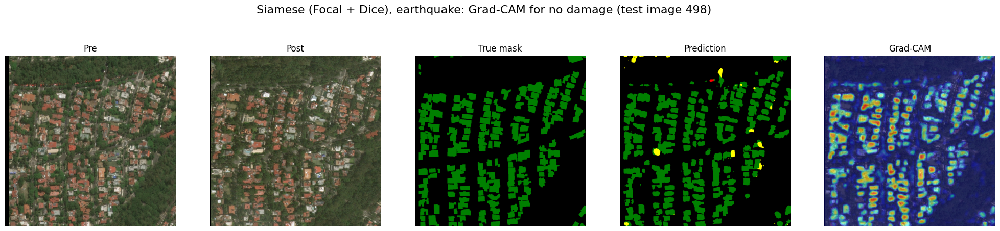

498 earthquake no damage | heat on buildings: 74.9 % | building area: 27.3 %


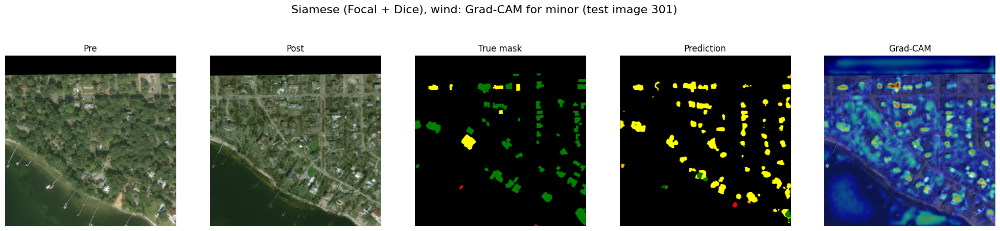

301 wind minor | heat on buildings: 17.4 % | building area: 6.8 %


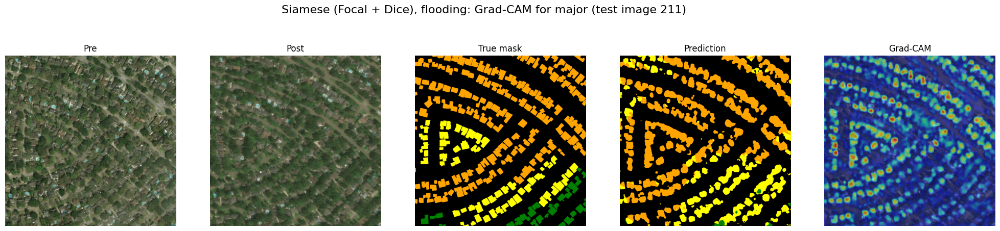

211 flooding major | heat on buildings: 61.6 % | building area: 31.5 %


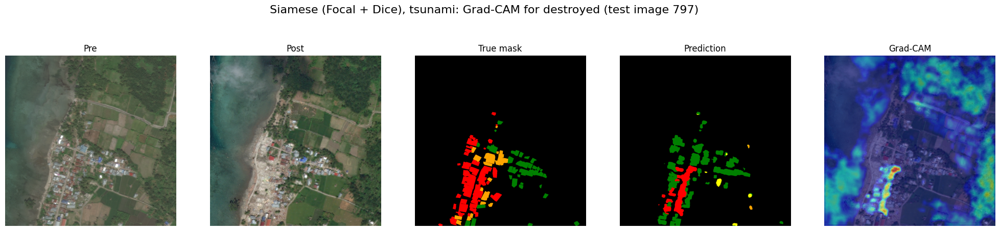

797 tsunami destroyed | heat on buildings: 7.0 % | building area: 8.3 %


In [10]:
examples = [
    (498, 1, "earthquake", "no damage", "gradcam_earthquake_no_damage.png"),
    (typical[("wind", 2)], 2, "wind", "minor", "gradcam_wind_minor.png"),
    (typical[("flooding", 3)], 3, "flooding", "major", "gradcam_flood_major_typical.png"),
    (typical[("tsunami", 4)], 4, "tsunami", "destroyed", "gradcam_tsunami_destroyed.png"),
]

for (idx, category, disaster, class_name, file_name) in examples:
    pre, post, mask, x = load_x(idx)
    heatmap, pred = compute_gradcam(siamese_cam, siamese_wrapper, x, category)
    heat, area = heat_on_buildings(heatmap, mask)

    title = "Siamese (Focal + Dice), " + disaster + ": Grad-CAM for " + class_name + " (test image " + str(idx) + ")"
    plot_example(pre, post, mask, pred, heatmap, title, save_path=FIG_DIR + file_name)
    plt.show()
    print(idx, disaster, class_name, "| heat on buildings:", round(heat * 100, 1), "% | building area:", round(area * 100, 1), "%")